In [1]:
## Ver la tabla y sus datos.
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../images", exist_ok=True)

df = pd.read_csv("../data/cafeteria.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df

,id_venta,fecha,dia,producto,categoria,turno,cantidad,precio_unitario
0,1,2026-03-01,Lunes,Cafe,Bebida,Manana,3,1.50
1,2,2026-03-01,Lunes,Te,Bebida,Manana,2,1.25
2,3,2026-03-01,Lunes,Empanada,Comida,Manana,4,2.00
3,4,2026-03-01,Lunes,Galleta,Snack,Tarde,5,0.80
4,5,2026-03-01,Lunes,Jugo,Bebida,Tarde,3,1.75
5,6,2026-03-02,Martes,Cafe,Bebida,Manana,4,1.50
6,7,2026-03-02,Martes,Empanada,Comida,Manana,2,2.00
7,8,2026-03-02,Martes,Pastel,Snack,Tarde,3,1.20
8,9,2026-03-02,Martes,Agua,Bebida,Tarde,6,1.00
9,10,2026-03-02,Martes,Te,Bebida,Noche,2,1.25


In [2]:
## Crear una columna total que sea igual a cantidad * precio unitario.
df["Total"] = df["cantidad"] * df["precio_unitario"]
df["Total"]

0      4.50
1      2.50
2      8.00
3      4.00
4      5.25
5      6.00
6      4.00
7      3.60
8      6.00
9      2.50
10     7.50
11     7.50
12     4.80
13     7.00
14     4.00
15     9.00
16     3.75
17     4.80
18     5.00
19     5.00
20    10.50
21    10.00
22     6.40
23     8.75
24     7.50
25     5.00
26     3.60
27     7.00
28     8.00
29     4.00
Name: Total, dtype: float64

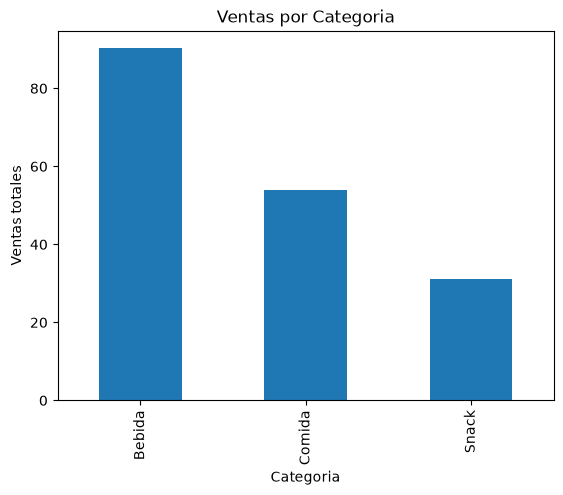

In [3]:
## Hacer una grafica de Barras ordenada que nos indique la venta por categoría.
ventas_categoria = df.groupby("categoria")["Total"].sum()
ventas_categoria = ventas_categoria.sort_values(ascending=False)

plt.figure()
ventas_categoria.plot(kind="bar")

plt.xlabel("Categoria")
plt.ylabel("Ventas totales")
plt.title("Ventas por Categoria")

plt.savefig("../images/ventas_por_categoria.png", dpi=150, bbox_inches="tight")
plt.show()

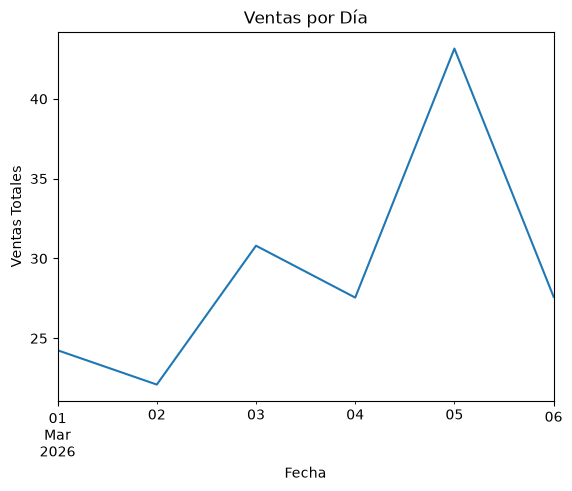

In [4]:
## Gráfica de línea indicando la venta por dia.
ventas_dia = df.groupby("fecha")["Total"].sum()

plt.figure()
ventas_dia.plot()
## Para mejora visual con punto la gráfica agregar: ventas_dia.plot(marker="o")

plt.xlabel("Fecha")
plt.ylabel("Ventas Totales")
plt.title("Ventas por Día")

plt.savefig("../images/ventas_por_dia.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
## Mostrar la Venta por Dia a través de índices.
df_indice = df.copy()
df_indice["fecha"] = df_indice["fecha"].dt.date
df_indice = df_indice.set_index("fecha")
ventas_dia_indice = df_indice["Total"].groupby(df_indice.index).sum()
resumen = df_indice.groupby("fecha").agg({"Total": "sum", "cantidad": "sum"}).reset_index()
resumen.columns = ["Fecha", "Ventas por día", "Cantidad total"]
resumen["Ventas por día"] = resumen["Ventas por día"].round(2)
resumen.style.format({"Ventas por día": "${:,.2f}"}).hide(axis="index")

Fecha,Ventas por día,Cantidad total
2026-03-01,$24.25,17
2026-03-02,$22.10,17
2026-03-03,$30.80,20
2026-03-04,$27.55,20
2026-03-05,$43.15,28
2026-03-06,$27.60,23


In [6]:
#Respuestas a las preguntas.
from IPython.display import display, Markdown

display(Markdown("# 📊 Análisis de Ventas"))

df_rel = df.copy()
df_rel["fecha"] = df_rel["fecha"].dt.date

relacion = df_rel.groupby(["fecha", "categoria"])["cantidad"].sum().reset_index()
tabla_relacion = relacion.pivot(index="fecha", columns="categoria", values="cantidad").fillna(0)

display(Markdown("### ¿Qué categoría vende más?"))
display(Markdown("Según los resultados presentados en nuestro primer gráfico de barras, la categoría que más vende en la cafetería son las bebidas 🥤."))

display(Markdown("### ¿Cuál fue el día que vendió más?"))
display(Markdown("De acuerdo con nuestro índice de ventas por fecha, el día más productivo fue el 5 de Marzo del 2026."))

display(Markdown("### ¿Crees que existe alguna relación entre categoría y día vendido? Favor elaborar."))

display(Markdown(f"""Para tener una respuesta más clara, analizamos las unidades vendidas por categoría y por cada fecha."""))
display(tabla_relacion.style)
display(Markdown("""Al analizar el resultado de esta tabla de múltiples días, nos damos cuenta que hay un patrón consistente como lo es las bebidas manteniéndose como la categoría más vendida todos los días lo que sugiere una alta demanda constante independientemente de las fechas. En el caso de los snacks presentan una ligera tendencia al aumento para los últimos días y en la categoría de la comida encontramos una fluctuación de demanda inconsistente. En base a estos resultados, concluimos que se puede inferir que si hay cierta relación entre las categorías y las fechas de venta, especialmente en el caso de las bebidas; Sin embargo, esta relación es menos clara en las otras dos categorías y pueden estar influenciadas por otros factores."""))

# 📊 Análisis de Ventas

### ¿Qué categoría vende más?

Según los resultados presentados en nuestro primer gráfico de barras, la categoría que más vende en la cafetería son las bebidas 🥤.

### ¿Cuál fue el día que vendió más?

De acuerdo con nuestro índice de ventas por fecha, el día más productivo fue el 5 de Marzo del 2026.

### ¿Crees que existe alguna relación entre categoría y día vendido? Favor elaborar.

Para tener una respuesta más clara, analizamos las unidades vendidas por categoría y por cada fecha.

categoria,Bebida,Comida,Snack
fecha,,,
2026-03-01,8,4,5
2026-03-02,12,2,3
2026-03-03,9,5,6
2026-03-04,14,2,4
2026-03-05,12,8,8
2026-03-06,11,4,8


Al analizar el resultado de esta tabla de múltiples días, nos damos cuenta que hay un patrón consistente como lo es las bebidas manteniéndose como la categoría más vendida todos los días lo que sugiere una alta demanda constante independientemente de las fechas. En el caso de los snacks presentan una ligera tendencia al aumento para los últimos días y en la categoría de la comida encontramos una fluctuación de demanda inconsistente. En base a estos resultados, concluimos que se puede inferir que si hay cierta relación entre las categorías y las fechas de venta, especialmente en el caso de las bebidas; Sin embargo, esta relación es menos clara en las otras dos categorías y pueden estar influenciadas por otros factores.